# **Albatul Altoum**

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Define augmentation and transforms
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),          # flip images randomly
    transforms.RandomCrop(32, padding=4),       # crop with padding
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Data loading block
batch_size = 32
num_workers = 2

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                             download=True, transform=transform_train)

test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                            download=True, transform=transform_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

print("Loaded CIFAR-10 successfully.")

Loaded CIFAR-10 successfully.


In [ ]:
from torch.utils.data import DataLoader

# Data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

# Training loop
num_epochs = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / total
    train_accuracy = correct / total

    # Evaluation
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        accuracy = 100 * correct / total
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss:.4f}, Accuracy: {accuracy:.2f}%")

    print("Finished Training CNN-style model.")
    model_cnn = model
    _ = evaluate_model(model_cnn, test_loader, "CNN-style model")

Epoch [1/10], Loss: 75098.5277, Accuracy: 55.86%
Finished Training CNN-style model.
CNN-style model Test Accuracy: 55.86%, Loss: 1.2215
Epoch [2/10], Loss: 59365.6141, Accuracy: 63.23%
Finished Training CNN-style model.
CNN-style model Test Accuracy: 63.23%, Loss: 1.0262
Epoch [3/10], Loss: 53151.4010, Accuracy: 66.75%
Finished Training CNN-style model.
CNN-style model Test Accuracy: 66.75%, Loss: 0.9326
Epoch [4/10], Loss: 48915.5372, Accuracy: 69.86%
Finished Training CNN-style model.
CNN-style model Test Accuracy: 69.86%, Loss: 0.8667
Epoch [5/10], Loss: 46221.0594, Accuracy: 71.45%
Finished Training CNN-style model.
CNN-style model Test Accuracy: 71.45%, Loss: 0.8301
Epoch [6/10], Loss: 44166.5385, Accuracy: 71.29%
Finished Training CNN-style model.
CNN-style model Test Accuracy: 71.29%, Loss: 0.8200
Epoch [7/10], Loss: 42356.5881, Accuracy: 70.70%
Finished Training CNN-style model.
CNN-style model Test Accuracy: 70.70%, Loss: 0.8382
Epoch [8/10], Loss: 41419.8706, Accuracy: 72.78%

In [ ]:
import torch.optim as optim

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize model, loss function, and optimizer
model_vgg = VGGStyleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_vgg.parameters(), lr=0.001)

# Training loop
num_epochs = 10
for epoch in range(num_epochs):
    running_loss = 0.0
    correct = 0
    total = 0

    model_vgg.train()
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()  # Clear gradients
        outputs = model_vgg(inputs)  # Forward pass
        loss = criterion(outputs, labels)  # Compute loss
        loss.backward()  # Backpropagation
        optimizer.step()  # Update weights

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss:.4f}, Accuracy: {accuracy:.2f}%")

print("Finished Training VGG-style model.")
evaluate_model(model_vgg, test_loader, "VGG-style CNN")

Epoch [1/10], Loss: 2377.3848, Accuracy: 44.33%
Epoch [2/10], Loss: 1721.4635, Accuracy: 60.55%
Epoch [3/10], Loss: 1434.6587, Accuracy: 67.80%
Epoch [4/10], Loss: 1289.1439, Accuracy: 70.91%
Epoch [5/10], Loss: 1180.7711, Accuracy: 73.69%
Epoch [6/10], Loss: 1099.0783, Accuracy: 75.47%
Epoch [7/10], Loss: 1055.9744, Accuracy: 76.30%
Epoch [8/10], Loss: 1003.7664, Accuracy: 77.71%
Epoch [9/10], Loss: 967.5105, Accuracy: 78.26%
Epoch [10/10], Loss: 926.1974, Accuracy: 79.26%
Finished Training VGG-style model.
VGG-style CNN Test Accuracy: 79.28%, Loss: 0.6245


(79.28, 0.6245037605301641)

In [ ]:
print(device)

cuda


In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock, self).__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = F.relu(out)
        return out

In [ ]:
class SimpleResNet(nn.Module):
    def __init__(self, num_classes=10):
        super(SimpleResNet, self).__init__()

        # Initial conv layer
        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)  # Output: [B, 64, 16, 16]
        )

        # Residual blocks
        self.layer2 = ResidualBlock(64, 128, stride=2)   # Output: [B, 128, 8, 8]
        self.layer3 = ResidualBlock(128, 256, stride=2)  # Output: [B, 256, 4, 4]

        # Global average pooling and fully connected layer
        self.avg_pool = nn.AdaptiveAvgPool2d((1, 1))      # Output: [B, 256, 1, 1]
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avg_pool(x)
        x = x.view(x.size(0), -1)  # Flatten
        x = self.fc(x)
        return x

In [ ]:
model_resnet = SimpleResNet().to(device)

In [ ]:
# Initialize model, loss function, and optimizer
model_resnet = SimpleResNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_resnet.parameters(), lr=0.001)

# Training loop
num_epochs = 10
for epoch in range(num_epochs):
    running_loss = 0.0
    correct = 0
    total = 0

    model_resnet.train()
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()                       # Clear gradients
        outputs = model_resnet(inputs)              # Forward pass
        loss = criterion(outputs, labels)           # Compute loss
        loss.backward()                             # Backpropagation
        optimizer.step()                            # Update weights

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss:.4f}, Accuracy: {accuracy:.2f}%")

print("Finished Training ResNet-style model.")
evaluate_model(model_resnet, test_loader, "ResNet-style CNN")

Epoch [1/10], Loss: 2122.0391, Accuracy: 50.68%
Epoch [2/10], Loss: 1553.6887, Accuracy: 64.82%
Epoch [3/10], Loss: 1287.0115, Accuracy: 71.13%
Epoch [4/10], Loss: 1133.3060, Accuracy: 74.75%
Epoch [5/10], Loss: 1022.4148, Accuracy: 77.19%
Epoch [6/10], Loss: 936.4824, Accuracy: 79.22%
Epoch [7/10], Loss: 880.8563, Accuracy: 80.51%
Epoch [8/10], Loss: 824.0854, Accuracy: 81.52%
Epoch [9/10], Loss: 783.3625, Accuracy: 82.65%
Epoch [10/10], Loss: 739.7462, Accuracy: 83.58%
Finished Training ResNet-style model.
ResNet-style CNN Test Accuracy: 83.05%, Loss: 0.5065


(83.05, 0.5064893851931483)

In [ ]:
def evaluate_model(model, dataloader, name="Model"):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0.0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(dataloader)

    print(f"{name} Test Accuracy: {accuracy:.2f}%, Loss: {avg_loss:.4f}")
    return accuracy, avg_loss

# Evaluate both models
evaluate_model(model_vgg, test_loader, "VGG-style CNN")
evaluate_model(model_resnet, test_loader, "ResNet-style CNN")
_ = evaluate_model(model_cnn, test_loader, "CNN-style model")

VGG-style CNN Test Accuracy: 79.28%, Loss: 0.6245
ResNet-style CNN Test Accuracy: 83.05%, Loss: 0.5065
CNN-style model Test Accuracy: 73.93%, Loss: 0.7513


In [ ]:
from sklearn.metrics import classification_report
import numpy as np

def evaluate_metrics(model, dataloader, name="Model"):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Generate classification report
    print(f"\n{name} - Classification Report:\n")
    print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

In [ ]:
evaluate_metrics(model_vgg, test_loader, name="VGG-style CNN")
evaluate_metrics(model_resnet, test_loader, name="ResNet-style CNN")
evaluate_metrics(model_cnn, test_loader, name="CNN-style model")


VGG-style CNN - Classification Report:

              precision    recall  f1-score   support

    airplane       0.80      0.84      0.82      1000
  automobile       0.90      0.91      0.90      1000
        bird       0.75      0.68      0.71      1000
         cat       0.65      0.58      0.61      1000
        deer       0.76      0.77      0.76      1000
         dog       0.74      0.69      0.71      1000
        frog       0.78      0.88      0.82      1000
       horse       0.75      0.89      0.82      1000
        ship       0.93      0.83      0.87      1000
       truck       0.89      0.86      0.87      1000

    accuracy                           0.79     10000
   macro avg       0.79      0.79      0.79     10000
weighted avg       0.79      0.79      0.79     10000


ResNet-style CNN - Classification Report:

              precision    recall  f1-score   support

    airplane       0.79      0.88      0.83      1000
  automobile       0.92      0.91      0.92    

In [ ]:
import matplotlib.pyplot as plt

def show_misclassified_images(model, dataloader, class_names, num_images=5):
    model.eval()
    wrong_images = []
    wrong_preds = []
    true_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            for i in range(len(preds)):
                if preds[i] != labels[i]:
                    wrong_images.append(inputs[i].cpu())
                    wrong_preds.append(preds[i].cpu().item())
                    true_labels.append(labels[i].cpu().item())
                if len(wrong_images) >= num_images:
                    break
            if len(wrong_images) >= num_images:
                break

    # Plot misclassified images
    plt.figure(figsize=(12, 6))
    for idx in range(num_images):
        img = wrong_images[idx].permute(1, 2, 0).numpy()
        img = (img - img.min()) / (img.max() - img.min())  # Normalize for display

        plt.subplot(1, num_images, idx + 1)
        plt.imshow(img)
        plt.title(f"True: {class_names[true_labels[idx]]}\nPred: {class_names[wrong_preds[idx]]}")
        plt.axis('off')

    plt.suptitle("Misclassified Images")
    plt.show()

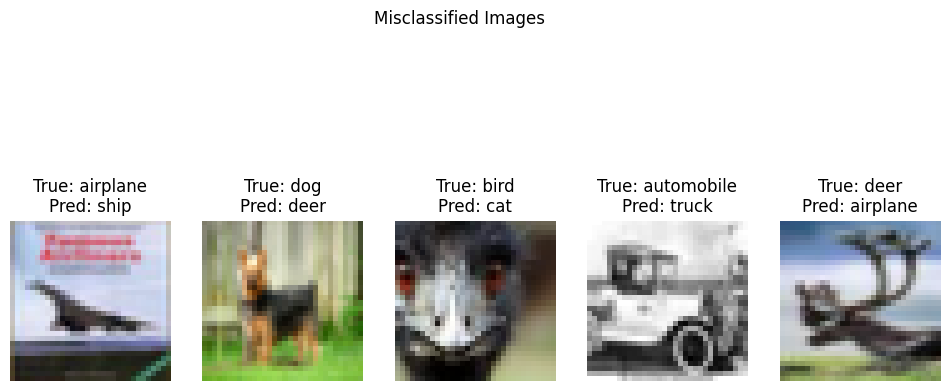

In [ ]:
show_misclassified_images(model_resnet, test_loader, train_dataset.classes, num_images=5)

In [ ]:
import torchvision.models as models

# Load pretrained ResNet18
from torchvision.models import resnet18, ResNet18_Weights

resnet18 = resnet18(weights=ResNet18_Weights.DEFAULT)

for param in resnet18.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match CIFAR-10 (10 classes)
resnet18.fc = nn.Linear(resnet18.fc.in_features, 10)

# Move model to GPU
resnet18 = resnet18.to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(resnet18.fc.parameters(), lr=0.001)

In [ ]:
num_epochs = 5
for epoch in range(num_epochs):
    resnet18.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = resnet18(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss:.4f}, Accuracy: {accuracy:.2f}%")

Epoch [1/5], Loss: 2876.2204, Accuracy: 35.20%
Epoch [2/5], Loss: 2764.0905, Accuracy: 38.01%
Epoch [3/5], Loss: 2744.6094, Accuracy: 38.22%
Epoch [4/5], Loss: 2748.2804, Accuracy: 38.12%
Epoch [5/5], Loss: 2739.1363, Accuracy: 38.54%


In [ ]:
evaluate_metrics(resnet18, test_loader, name="Transfer Learning - ResNet18")


Transfer Learning - ResNet18 - Classification Report:

              precision    recall  f1-score   support

    airplane       0.39      0.28      0.32      1000
  automobile       0.47      0.37      0.41      1000
        bird       0.32      0.35      0.33      1000
         cat       0.30      0.45      0.36      1000
        deer       0.43      0.37      0.40      1000
         dog       0.42      0.16      0.23      1000
        frog       0.37      0.63      0.46      1000
       horse       0.52      0.36      0.43      1000
        ship       0.35      0.54      0.42      1000
       truck       0.45      0.32      0.38      1000

    accuracy                           0.38     10000
   macro avg       0.40      0.38      0.38     10000
weighted avg       0.40      0.38      0.38     10000



In [ ]:
pip install grad-cam

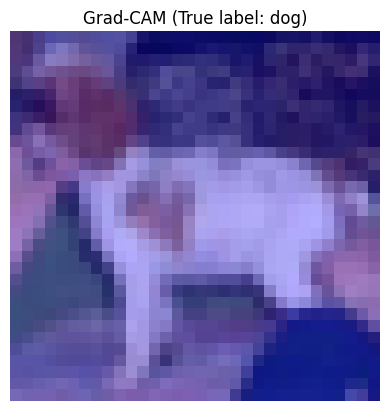

In [ ]:
# Load pretrained ResNet18
from torchvision.models import resnet18, ResNet18_Weights

resnet18 = resnet18(weights=ResNet18_Weights.DEFAULT)

for param in resnet18.parameters():
    param.requires_grad = True


resnet18.fc = nn.Linear(resnet18.fc.in_features, 10)


resnet18 = resnet18.to(device)
# Step 1: Import required tools
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
import numpy as np

# Step 2: Add reshape_transform for ResNet
def reshape_transform(tensor):
    return tensor

# Step 3: Select a test image from CIFAR-10
image_tensor, label = test_dataset[12]  # You can change the index to try other images
input_tensor = image_tensor.unsqueeze(0).to(device)

# Convert image to [0, 1] for visualization
rgb_img = image_tensor.permute(1, 2, 0).numpy()
rgb_img = (rgb_img - rgb_img.min()) / (rgb_img.max() - rgb_img.min())

# Step 4: Define the target layer from ResNet
target_layer = resnet18.layer4[-1]

# Step 5: Initialize GradCAM++
cam = GradCAMPlusPlus(
    model=resnet18,
    target_layers=[resnet18.layer4[-1]],
    reshape_transform=reshape_transform

# Step 6: Set the target class (true label)
targets = [ClassifierOutputTarget(label)]

# Step 7: Generate the Grad-CAM mask
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
grayscale_cam = grayscale_cam[0]

# Step 8: Overlay the heatmap on the original image
visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

# Step 9: Display the result
plt.imshow(visualization)
plt.title(f"Grad-CAM (True label: {train_dataset.classes[label]})")
plt.axis('off')
plt.show()

In this project, I designed a Convolutional Neural Network (CNN) from scratch and trained it on the CIFAR-10 dataset.
I started with building a simple model to better understand how each part of the architecture affects the overall performance.
First, I used convolutional layers combined with ReLU activation functions because they are essential in CNNs.
The convolutional layers help extract important features from the images, while ReLU introduces non-linearity, allowing the model to learn more complex patterns.

After each set of convolutional layers, I added a MaxPooling layer. The goal of pooling is to gradually reduce the spatial dimensions of the data, which helps decrease the number of parameters, reduces overfitting, and speeds up training.

I also included Dropout layers during training as a regularization technique to prevent the model from simply memorizing the training data. Instead, it encourages the model to learn more generalizable features.

For optimization, I used the Adam optimizer because it is efficient, adapts the learning rate during training, and helps the model converge faster, especially when training smaller or medium-sized networks.

I applied simple data augmentation techniques such as horizontal flipping and random changes to the images. Since CIFAR-10 is a relatively small dataset, augmentation helps the model generalize better and avoid overfitting.

Later on, I expanded the project by comparing two popular pretrained architectures: VGG and ResNet.
I chose VGG because it is simple and structured mainly with repeated convolutional layers, while ResNet is known for using skip connections, which solve the vanishing gradient problem and allow deeper networks to train effectively.

Finally, I used Grad-CAM to visualize where the model focuses when making predictions.
This technique helped me understand whether the model was making decisions based on important regions of the images or not.